# Single-patch workflow

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
A practical, end-to-end workflow for super-resolving a single image patch
</div>
<!-- markdownlint-enable MD033 -->

---

You now understand what {term}`LDSR-S2` does internally. This page runs it, on a real Sentinel-2 scene of Granada, Spain, on a single patch, before later pages add uncertainty estimation and scale up to larger regions.

---

## 1. Motivation

This is the page where the previous three pages' concepts become an actual enhanced image. Downloading, inspecting, and verifying the data before and after processing is not a formality; it is what confirms the output is genuinely usable in a GIS workflow, not just visually convincing. Comparing the result against simple interpolation, and checking what the model kept from the input, is what tells you what the model actually added.

---

## 2. Core idea

The workflow has a consistent shape: download and inspect the input imagery, locate the patch you want to enhance, run {term}`super-resolution <Super-Resolution>`, compare the result against both the input and a simple interpolation, check that the output still agrees with the measured 10 m values, and verify its {term}`georeferencing <Georeferencing>` before trusting it for anything further.

---

## 3. Workflow

### A. Download and inspect the data

In [1]:
import contextlib
import io
import time
import warnings

import geoai
import numpy as np
import rasterio as rio
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
from rasterio.enums import Resampling
from rasterio.windows import Window

warnings.filterwarnings("ignore")

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L09/data/S2A_L2A_20260802_N0512_R094_subset_Granada.tif"
s2_path = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

with rio.open(s2_path) as src:
    print(f"Bands: {src.count} {src.descriptions}")
    print(f"Size: {src.width} x {src.height}")
    print(f"CRS: {src.crs}")
    print(f"Resolution: {src.res[0]:.2f} m")
    print(f"Dtype: {src.dtypes[0]}")

Bands: 4 ('B4', 'B3', 'B2', 'B8')
Size: 3000 x 1500
CRS: EPSG:32630
Resolution: 10.00 m
Dtype: uint16


This is a Sentinel-2A Level-2A subset over Granada, Spain, acquired on 2 August 2026, covering the city and the surrounding irrigated farmland of the Vega de Granada. It contains four 10-meter bands (red, green, blue, {term}`near-infrared <Near-Infrared>`; B4, B3, B2, B8), already in the order LDSR-S2 expects, stored as `uint16` surface reflectance values ranging from 0 to 10,000, where a value of 1,000 corresponds to 10% reflectance. This value range is standard for Sentinel-2 L2A products; do not mistake it for an already-8-bit image.

### B. Show the scene and locate the patch

LDSR-S2 works on patches of 128 × 128 pixels, which at 10 m is 1.28 × 1.28 km. The rectangle shows the patch used on this page and the next; the dashed square is the larger area page 7 processes.

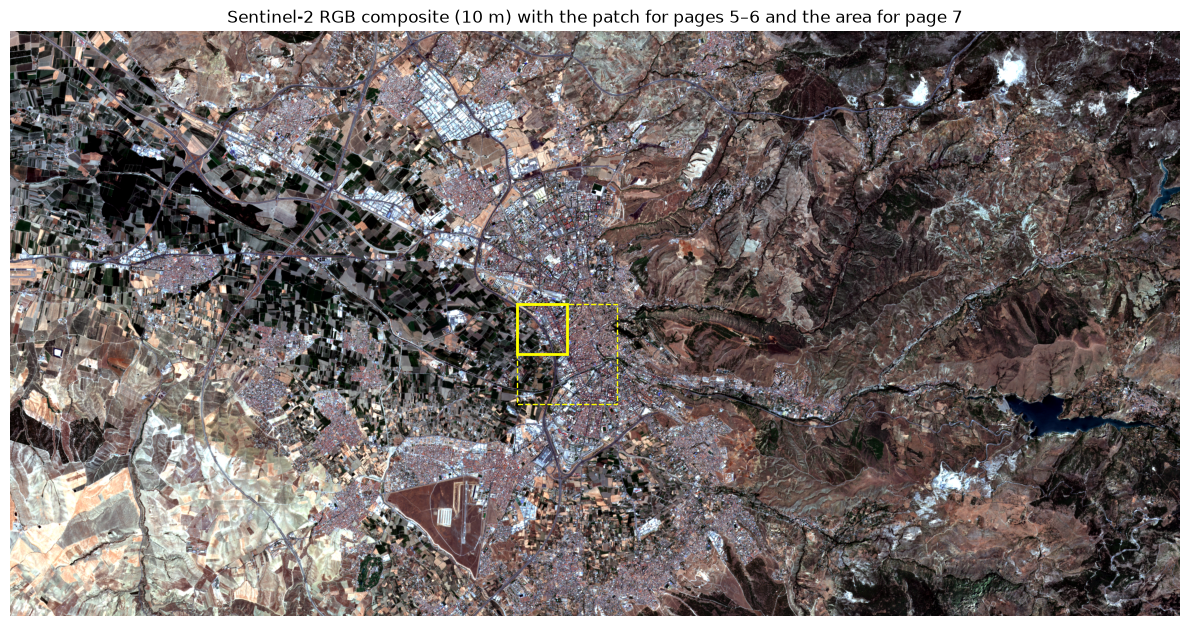

In [2]:
ROW, COL, SIZE = 700, 1300, 128  # patch position (row and column offset) and size in pixels

with rio.open(s2_path) as src:
    rgb = src.read([1, 2, 3]).astype(np.float32)

lo = np.percentile(rgb, 2, axis=(1, 2), keepdims=True)
hi = np.percentile(rgb, 98, axis=(1, 2), keepdims=True)
rgb = np.clip((rgb - lo) / (hi - lo), 0, 1)

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(rgb.transpose(1, 2, 0))
ax.add_patch(Rectangle((COL, ROW), SIZE, SIZE, fill=False, edgecolor="yellow", linewidth=2))
ax.add_patch(Rectangle((COL, ROW), 2 * SIZE, 2 * SIZE, fill=False, edgecolor="yellow", linestyle="--"))
ax.set_title("Sentinel-2 RGB composite (10 m) with the patch for pages 5–6 and the area for page 7")
ax.set_axis_off()
plt.tight_layout()
plt.show()

The percentile stretch maps the 2nd and 98th percentile values of each band to 0 and 1, a standard contrast-enhancement step that improves visual interpretability without letting a handful of extreme pixel values wash out the rest of the image. The patch lies on the south-western edge of the city, where the ring road separates dense blocks of flats from the fields of the Vega: a useful mix of sharp urban structure and homogeneous fields.

### C. Run single-patch super-resolution

In [3]:
sr_output = str(OUT_DIR / "sr_output.tif")

start = time.perf_counter()
with contextlib.redirect_stdout(io.StringIO()):  # hide the model's loading messages
    sr_image, _ = geoai.super_resolution(
        input_lr_path=s2_path,
        output_sr_path=sr_output,
        rgb_nir_bands=[1, 2, 3, 4],
        window=(ROW, COL, SIZE, SIZE),
        sampling_steps=10,
    )

print(f"Input shape: (4, {SIZE}, {SIZE}) at 10 m")
print(f"Output shape: {sr_image.shape} at 2.5 m")
print(f"Runtime: {time.perf_counter() - start:.0f} s")

Input shape: (4, 128, 128) at 10 m
Output shape: (4, 512, 512) at 2.5 m
Runtime: 38 s


`window=(ROW, COL, SIZE, SIZE)` specifies `(row_offset, col_offset, height, width)` in pixel coordinates, extracting one 128-by-128 patch, LDSR-S2's native input size, from the larger scene. `sampling_steps` sets how many denoising steps the diffusion process runs. Each call also loads the model, which takes roughly 15–20 seconds on its own, before any patch is processed.

```{admonition} Runs on the CPU, unless you have an NVIDIA GPU
:class: note
`geoai.super_resolution()` uses an NVIDIA {term}`GPU` ({term}`CUDA`) if one is available and the {abbr}`CPU (central processing unit)` otherwise; it does not use the Apple Silicon GPU. On a laptop CPU, one patch takes well under a minute with 10 steps. On Google Colab with a GPU, it takes a few seconds.
```

### D. How many sampling steps?

`geoai`'s default is `sampling_steps=100`, the number the original sampler of this model needed. Current versions of the underlying `opensr-model` package use a faster sampler ({abbr}`DPM-Solver++ (a fast solver for diffusion probabilistic models)`), which needs far fewer steps. The code below runs the same patch with 3 and 100 steps, to compare against the 10-step result from step C.

In [4]:
def sharpness(img):
    """Mean edge strength of the RGB brightness: higher means sharper."""
    gy, gx = np.gradient(img[:3].mean(axis=0))
    return np.hypot(gx, gy).mean()

results = {10: sr_image}
for steps in [3, 100]:
    start = time.perf_counter()
    with contextlib.redirect_stdout(io.StringIO()):
        results[steps], _ = geoai.super_resolution(
            input_lr_path=s2_path,
            output_sr_path=str(OUT_DIR / f"sr_steps_{steps}.tif"),
            window=(ROW, COL, SIZE, SIZE),
            sampling_steps=steps,
        )
    print(f"{steps:>3} steps: {time.perf_counter() - start:4.0f} s")

for steps in sorted(results):
    print(f"{steps:>3} steps: sharpness {sharpness(results[steps]):.4f}")

  3 steps:   21 s


100 steps:   96 s
  3 steps: sharpness 0.0151
 10 steps: sharpness 0.0174
100 steps: sharpness 0.0181


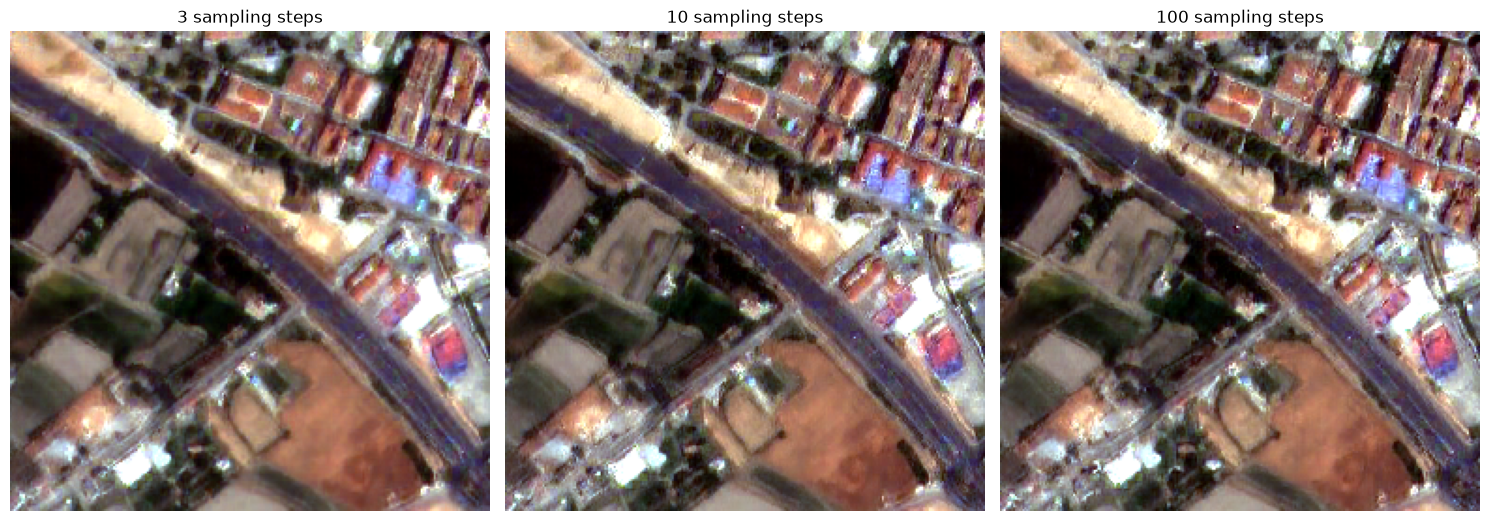

In [5]:
# Shared contrast stretch from the 10 m input, applied to every panel for a fair comparison
with rio.open(s2_path) as src:
    lr = src.read(window=Window(COL, ROW, SIZE, SIZE)).astype(np.float32) / 10_000
p2 = np.percentile(lr[:3], 2, axis=(1, 2), keepdims=True)
p98 = np.percentile(lr[:3], 98, axis=(1, 2), keepdims=True)

def show(img):
    """Return an RGB image (height, width, 3) stretched with the shared percentiles."""
    return np.clip((img[:3] - p2) / (p98 - p2), 0, 1).transpose(1, 2, 0)

zoom = (slice(0, 256), slice(0, 256))  # upper-left quarter of the 512 x 512 output
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, steps in zip(axes, [3, 10, 100]):
    ax.imshow(show(results[steps][:, zoom[0], zoom[1]]))
    ax.set_title(f"{steps} sampling steps")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

The step count shows diminishing returns: 3 steps give a slightly smoother image, while 10 and 100 steps look almost identical, yet 100 steps take several times longer. This page and the next two therefore use 10 steps. Notice also that the three images differ in small details, such as the pattern of individual roofs, even where they are equally sharp. That is not caused by the step count alone: the model starts from random noise, so *every run* produces a slightly different image. Page 6 turns this into a measure of uncertainty.

### E. Compare against interpolation

A super-resolved image always looks sharper than the original 10 m pixels. The fair comparison is against **{term}`bicubic interpolation <Bicubic Interpolation>`** to the same 2.5 m pixel size, which adds pixels but no new structure.

Sharpness  bicubic: 0.0088   super-resolved: 0.0174


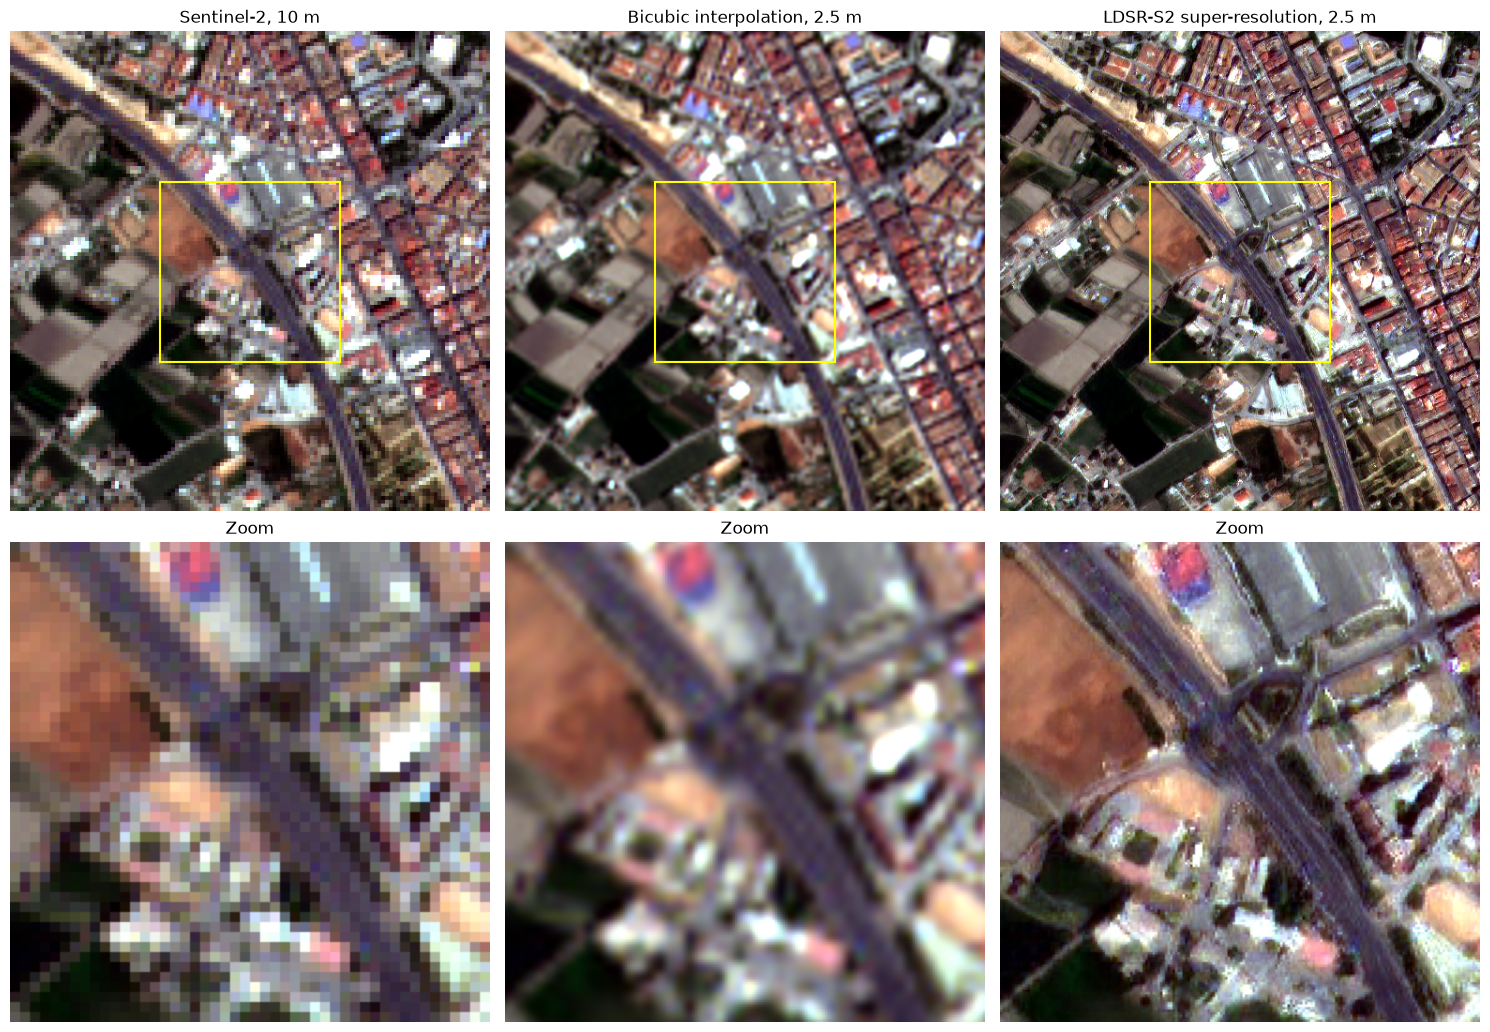

In [6]:
with rio.open(s2_path) as src:
    bicubic = src.read(
        window=Window(COL, ROW, SIZE, SIZE),
        out_shape=(4, SIZE * 4, SIZE * 4),
        resampling=Resampling.cubic,
    ).astype(np.float32) / 10_000

print(f"Sharpness  bicubic: {sharpness(bicubic):.4f}   super-resolved: {sharpness(sr_image):.4f}")

zoom = (slice(160, 352), slice(160, 352))  # 192 x 192 output pixels = 480 x 480 m
panels = {
    "Sentinel-2, 10 m": np.kron(lr, np.ones((1, 4, 4))),  # each 10 m pixel repeated 4 x 4
    "Bicubic interpolation, 2.5 m": bicubic,
    "LDSR-S2 super-resolution, 2.5 m": sr_image,
}
fig, axes = plt.subplots(2, 3, figsize=(15, 10.5))
for col, (title, img) in enumerate(panels.items()):
    axes[0, col].imshow(show(img))
    axes[0, col].add_patch(Rectangle((zoom[1].start, zoom[0].start), 192, 192,
                                     fill=False, edgecolor="yellow", linewidth=1.5))
    axes[0, col].set_title(title)
    axes[1, col].imshow(show(img[:, zoom[0], zoom[1]]))
    axes[1, col].set_title("Zoom")
for ax in axes.ravel():
    ax.set_axis_off()
plt.tight_layout()
plt.show()

The bicubic image (centre) is smoother than the 10 m pixels but no more detailed: every roof is still a soft blob. The super-resolved image (right) draws crisp building outlines, individual roofs, lane edges along the ring road and sharp field boundaries, roughly twice the edge strength of the bicubic result. In the zoom, the junction below the ring road even becomes a neat roundabout. Whether that roundabout really exists, the 10 m input alone cannot tell you; page 7 checks it against aerial imagery. This is exactly the detail the 10 m sensor did not resolve, which is why the remaining steps check what the model kept from the input, and pages 6 and 7 check how reliable the new detail is.

`geoai` also provides a quick side-by-side plot, `geoai.plot_sr_comparison(s2_path, sr_output)`. It stretches each image separately, so brightness differences between the two panels are partly a display effect; the shared stretch used above avoids that.

### F. Check what the model kept

LDSR-S2 ends with a correction step (page 4): it adjusts its output so that every 4 × 4 block of 2.5 m pixels averages exactly to the original 10 m value. You can verify this by averaging the output back to 10 m:

In [7]:
sr_10m = sr_image.reshape(4, SIZE, 4, SIZE, 4).mean(axis=(2, 4))  # average each 4 x 4 block

for name, i in zip(["red", "green", "blue", "NIR"], range(4)):
    diff = np.abs(sr_10m[i] - lr[i]).max()
    print(f"{name:>5}: largest difference to the 10 m input = {diff:.6f}")

def ndvi(img):
    return (img[3] - img[0]) / (img[3] + img[0])

print(f"\nMean NDVI  10 m input: {ndvi(lr).mean():.4f}   SR averaged to 10 m: {ndvi(sr_10m).mean():.4f}")

subpixel_sd = sr_image.reshape(4, SIZE, 4, SIZE, 4).std(axis=(2, 4))
print(f"Typical variation inside one 10 m pixel (red band): {np.median(subpixel_sd[0]):.4f} reflectance")

  red: largest difference to the 10 m input = 0.000000
green: largest difference to the 10 m input = 0.000000
 blue: largest difference to the 10 m input = 0.000000
  NIR: largest difference to the 10 m input = 0.000000

Mean NDVI  10 m input: 0.2715   SR averaged to 10 m: 0.2715
Typical variation inside one 10 m pixel (red band): 0.0173 reflectance


At 10 m, nothing changed: the averages match the input to within rounding, and so does {term}`NDVI <Normalized Difference Vegetation Index>`. The model does not alter what the sensor measured. What it adds is the **distribution inside each 10 m pixel**: which of the sixteen 2.5 m sub-pixels is roof and which is street. The last line shows how large that added variation is: the sixteen sub-pixels of a 10 m pixel typically differ by about 0.017 reflectance (standard deviation, red band), variation the sensor never resolved. That distribution is generated. The NDVI maps below make the difference visible:

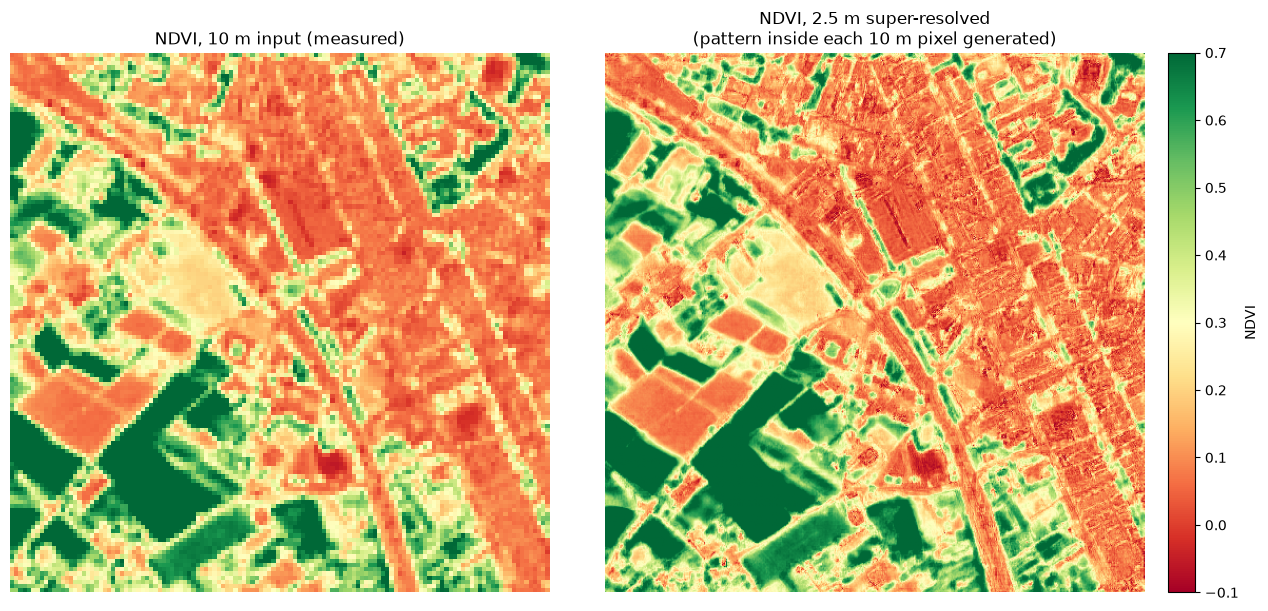

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
for ax, (title, img) in zip(axes, [("NDVI, 10 m input (measured)", lr),
                                   ("NDVI, 2.5 m super-resolved\n(pattern inside each 10 m pixel generated)", sr_image)]):
    im = ax.imshow(ndvi(img), cmap="RdYlGn", vmin=-0.1, vmax=0.7)
    ax.set_title(title)
    ax.set_axis_off()
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label="NDVI")
plt.show()

Both maps agree on the 10 m averages, but the right-hand map shows individual tree crowns, garden strips and field edges at 2.5 m. They are plausible, and many will be right, but the sensor never measured them at that scale.

### G. Verify the output's georeferencing

In [9]:
with rio.open(s2_path) as src:
    expected = rio.windows.bounds(Window(COL, ROW, SIZE, SIZE), src.transform)

with rio.open(sr_output) as src:
    print(f"SR Bands: {src.count}")
    print(f"SR Size: {src.width} x {src.height}")
    print(f"SR CRS: {src.crs}")
    print(f"SR Resolution: {src.res[0]:.2f} m")
    print(f"Same footprint as the input patch: {np.allclose(tuple(src.bounds), expected)}")

SR Bands: 4
SR Size: 512 x 512
SR CRS: EPSG:32630
SR Resolution: 2.50 m
Same footprint as the input patch: True


Confirming the output {term}`CRS <Coordinate Reference System>` matches the input, that the resolution is genuinely 2.5 meters, and that the footprint is exactly the input patch, matters because it is what makes the enhanced output directly usable in GIS software, aligned with your other project data, rather than a plausible-looking image with no reliable spatial reference.

---

## 4. Python reactivation

- `with contextlib.redirect_stdout(io.StringIO()):` temporarily sends everything a function prints into an in-memory text buffer instead of the screen; here it hides the model's loading messages. Errors are still shown.
- `time.perf_counter()` returns a clock value in seconds; the difference between two calls is the elapsed time.
- `src.read(window=..., out_shape=..., resampling=Resampling.cubic)` reads a raster window and resamples it to a different shape in one step.
- `img.reshape(4, 128, 4, 128, 4).mean(axis=(2, 4))` splits each axis of a 512 × 512 image into 128 blocks of 4 pixels and averages over the two within-block axes: a fast way to aggregate 2.5 m pixels back to 10 m.
- `np.kron(lr, np.ones((1, 4, 4)))` repeats every pixel 4 × 4 times, which enlarges an image without any smoothing (nearest-neighbour).

---

## 5. Common pitfalls

- **Misreading the `window` parameter order.** It is `(row_offset, col_offset, height, width)`, not `(x, y, width, height)`; double-check this if your patch appears in an unexpected location.
- **Treating raw `uint16` reflectance values as an ordinary 0–255 image.** Sentinel-2 L2A reflectance values range from 0 to 10,000; `geoai.super_resolution()` divides by 10,000 internally, but your own plotting code must account for it.
- **Comparing against the 10 m pixels only.** Every 2.5 m image looks sharper than blocky 10 m pixels; compare against bicubic interpolation to see what the model really added.
- **Comparing images with different contrast stretches.** Stretch both images with the same values, or brightness differences become part of what you think you see.
- **Skipping the georeferencing check in step G.** A visually convincing output with broken or missing georeferencing is not usable in a GIS workflow, however good it looks.
- **Using the default `sampling_steps=100` without checking.** With the current sampler, 10 steps give nearly the same result in a fraction of the time; test on your own hardware.

---

## 6. Mini task

Without changing any code, predict what would happen if you changed the window to `(700, 1300, 64, 64)`. Would this be a valid input for LDSR-S2 as described on the previous page? What window would you use for a 1 × 1 km area instead?

:::{dropdown} Sample solution
:class: note

It fails with a `ValueError`. LDSR-S2 was trained on 128 × 128 input patches, and the current model accepts side lengths between 100 and 128 pixels (smaller ones within that range are padded to 128 internally). A 64 × 64 patch is too small, so the model refuses it rather than producing a smaller output. Windows *larger* than 128 pixels are fine, because `geoai` then cuts them into 128-pixel tiles (page 7).

A 1 × 1 km area at 10 m is 100 × 100 pixels, for example `window=(700, 1300, 100, 100)`, which is just inside the accepted range and returns a 400 × 400 pixel output at 2.5 m.
:::

---

## 7. Key takeaways

- `geoai.super_resolution()` runs the full encode-denoise-decode pipeline from the previous page on a specified window of a Sentinel-2 scene.
- The `window` parameter uses `(row_offset, col_offset, height, width)` pixel coordinates; single patches must be 100–128 pixels per side.
- With the current sampler, about 10 `sampling_steps` are enough; more steps add runtime but little sharpness.
- Compared with bicubic interpolation, super-resolution adds sharp structure; averaged back to 10 m, the output matches the input exactly. Everything the model adds lies *inside* each 10 m pixel.
- Always verify the output's CRS, size, footprint and resolution before treating it as usable; a convincing image is not the same as a correctly georeferenced one.

### Further reading

- {abbr}`ESA (European Space Agency)` OpenSR, ["opensr-model"](https://github.com/ESAOpenSR/opensr-model) — documentation of LDSR-S2, its sampler options and the consistency correction.
- Lu et al. (2022), ["DPM-Solver++: Fast Solver for Guided Sampling of Diffusion Probabilistic Models"](https://arxiv.org/abs/2211.01095) — the sampler that makes a handful of steps sufficient.